# Practice 2, used dataset - Churn_Modeling


Task 1 Data Exploration
I used the Churn Modelling dataset. It contains information about bank customers, and the target column is Exited: 1 means the customer left the bank and 0 means the customer stayed
Dataset URL: https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

df = pd.read_csv("Churn_Modelling.csv")

df.shape

(10000, 14)

In [2]:
df.info()
display(df.head())

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Missing values: 0
Duplicate rows: 0


In [3]:
num_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

cat_cols = [
    "Geography",
    "Gender",
    "HasCrCard",
    "IsActiveMember"
]

target = "Exited"

The dataset has 10000 rows and 14 columns. There are no missing values or duplicate rows. I excluded RowNumber, CustomerId and Surname from the features because they describe row numbers or customer identities

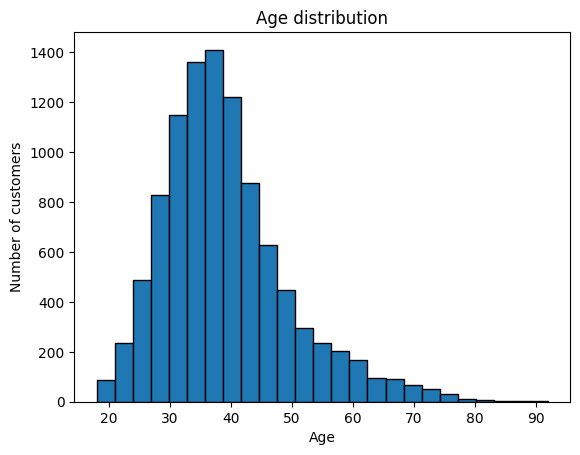

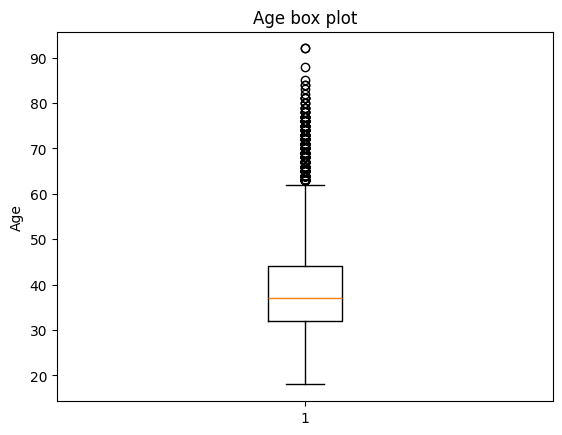

In [4]:
#1a
plt.hist(df["Age"], bins=25, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Number of customers")
plt.title("Age distribution")
plt.show()

plt.boxplot(df["Age"])
plt.ylabel("Age")
plt.title("Age box plot")
plt.show()

In [5]:
# finding outliers
q1 = df["Age"].quantile(0.25)
q3 = df["Age"].quantile(0.75)

iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

bounds = pd.DataFrame({
    "Q1": [q1],
    "Q3": [q3],
    "IQR": [iqr],
    "Lower bound": [lower_bound],
    "Upper bound": [upper_bound]
})

display(bounds)

age_outliers = df[
    (df["Age"] < lower_bound) |
    (df["Age"] > upper_bound)
]

print("Number of outliers:", len(age_outliers))

# show the full list
with pd.option_context("display.max_rows", None):
    display(age_outliers[["RowNumber", "Age"]])

,Q1,Q3,IQR,Lower bound,Upper bound
0,32.0,44.0,12.0,14.0,62.0


Number of outliers: 359


,RowNumber,Age
58,59,66
85,86,75
104,105,65
158,159,73
181,182,65
230,231,72
234,235,67
243,244,67
252,253,79
310,311,80


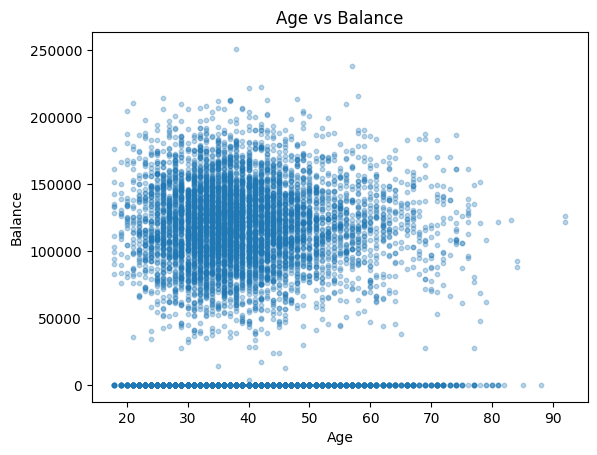

In [6]:
#1b
plt.scatter(df["Age"], df["Balance"], alpha=0.3, s=10)
plt.xlabel("Age")
plt.ylabel("Balance")
plt.title("Age vs Balance")
plt.show()

Task 1 Data Exploration

Most customers are around 30 to 45 years old, and the age distribution has a longer right tail. Q1 is 32, Q3 is 44 and IQR is 12, so the lower and upper bounds are 14 and 62. The IQR method found 359 outliers, all older than 62
The scatter plot does not show a clear positive or negative relationship between Age and Balance. Customers of similar ages can have very different balances, and many customers have a zero balance

In [7]:
#2
x = df["Age"]

log_x = np.log(x + 1)
minmax_x = (x - x.min()) / (x.max() - x.min())
zscore_x = (x - x.mean()) / x.std()

transformed = pd.DataFrame({
    "Original": x,
    "Log": log_x,
    "Min-Max": minmax_x,
    "Z-score": zscore_x
})

transformation_table = transformed.agg(
    ["min", "max", "mean", "std"]
).T

display(transformation_table)

,min,max,mean,std
Original,18.000000,92.000000,3.892180e+01,10.487806
Log,2.944439,4.532599,3.654701e+00,0.251651
Min-Max,0.000000,1.000000,2.827270e-01,0.141727
Z-score,-1.994869,5.060944,2.383871e-16,1.000000


Task 2 Variable Transformation

The log transformation compresses larger age values. Min-Max puts the values between 0 and 1, while Z-score gives a mean close to 0 and a standard deviation of 1
I would use Min-Max before computing distances and apply it to each numeric attribute. This puts the features on the same range, so large values such as salary do not dominate the result just because of their units

In [8]:
# sample of 10 customers
sample = df.sample(n=10, random_state=42).copy()

display(sample[["RowNumber"] + num_cols + cat_cols])

row_numbers = sample["RowNumber"].to_numpy()

# normalize using the full dataset ranges
numeric_normalized = (
    (df[num_cols] - df[num_cols].min()) /
    (df[num_cols].max() - df[num_cols].min())
)

X_sample = numeric_normalized.loc[sample.index].to_numpy()

,RowNumber,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography,Gender,HasCrCard,IsActiveMember
6252,6253,596,32,3,96709.07,2,41788.37,Germany,Male,0,0
4684,4685,623,43,1,0.00,2,146379.30,France,Male,1,1
1731,1732,601,44,4,0.00,2,58561.31,Spain,Female,1,0
4742,4743,506,59,8,119152.10,2,170679.74,Germany,Male,1,1
4521,4522,560,27,7,124995.98,1,114669.79,Spain,Female,1,1
6340,6341,790,37,8,0.00,2,149418.41,Spain,Male,1,1
576,577,439,32,3,138901.61,1,75685.97,Spain,Female,1,0
5202,5203,597,22,6,101528.61,1,70529.00,Germany,Female,1,0
6363,6364,678,40,4,113794.22,1,16618.76,Spain,Female,1,0
439,440,464,42,3,85679.25,1,164104.74,Germany,Female,1,1


In [9]:
# distances
euclidean = squareform(pdist(X_sample, metric="euclidean"))
manhattan = squareform(pdist(X_sample, metric="cityblock"))
minkowski = squareform(
    pdist(X_sample, metric="minkowski", p=3)
)

# cosine similarity
dot_products = X_sample @ X_sample.T
norms = np.linalg.norm(X_sample, axis=1)

cosine = dot_products / np.outer(norms, norms)

In [10]:
# categorical representation for jaccard
binary_data = pd.get_dummies(df[cat_cols].astype(str))
binary_sample = binary_data.loc[sample.index]

category_sets = []

for i in range(len(binary_sample)):
    active_categories = binary_sample.columns[
        binary_sample.iloc[i].to_numpy() == 1
    ]
    category_sets.append(set(active_categories))


def jaccard(list1, list2):
    intersection = len(set(list1) & set(list2))
    union = len(set(list1) | set(list2))
    return intersection / union


jaccard_similarity = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        jaccard_similarity[i, j] = jaccard(
            category_sets[i], category_sets[j]
        )

In [11]:
# show all pairwise matrices
matrices = {
    "Euclidean": euclidean,
    "Manhattan": manhattan,
    "Minkowski p=3": minkowski,
    "Jaccard": jaccard_similarity,
    "Cosine": cosine
}

for name, matrix in matrices.items():
    print(name)

    display(pd.DataFrame(
        matrix,
        index=row_numbers,
        columns=row_numbers
    ).round(4))

Euclidean


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,0.0000,0.6979,0.4382,0.9159,0.6530,0.9183,0.5164,0.4903,0.4245,0.7584
4685,0.6979,0.0000,0.5338,0.9120,0.8984,0.7800,0.8603,0.8672,0.9174,0.6139
1732,0.4382,0.5338,0.0000,0.8815,0.7665,0.7199,0.7525,0.6379,0.6224,0.7695
4743,0.9159,0.9120,0.8815,0.0000,0.6315,0.8049,0.8626,0.8306,1.0244,0.6632
4522,0.6530,0.8984,0.7665,0.6315,0.0000,0.7933,0.5140,0.2784,0.6473,0.5689
6341,0.9183,0.7800,0.7199,0.8049,0.7933,0.0000,1.1406,0.8128,0.9847,0.9554
577,0.5164,0.8603,0.7525,0.8626,0.5140,1.1406,0.0000,0.4806,0.5894,0.5111
5203,0.4903,0.8672,0.6379,0.8306,0.2784,0.8128,0.4806,0.0000,0.4477,0.6758
6364,0.4245,0.9174,0.6224,1.0244,0.6473,0.9847,0.5894,0.4477,0.0000,0.8662
440,0.7584,0.6139,0.7695,0.6632,0.5689,0.9554,0.5111,0.6758,0.8662,0.0000


Manhattan


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,0.0000,1.3111,0.7415,1.7788,1.3501,1.8792,0.9850,0.9334,0.8994,1.3881
4685,1.3111,0.0000,0.7966,1.7466,1.9323,1.1303,1.9571,1.9531,1.8863,1.2950
1732,0.7415,0.7966,0.0000,1.8283,1.7238,1.3269,1.5587,1.3031,1.2047,1.6036
4743,1.7788,1.7466,1.8283,0.0000,1.2771,1.4465,1.8859,1.7864,2.1258,1.3134
4522,1.3501,1.9323,1.7238,1.2771,0.0000,1.7004,0.9599,0.5558,1.2466,1.1986
6341,1.8792,1.1303,1.3269,1.4465,1.7004,0.0000,2.5252,1.9212,2.1155,1.9678
577,0.9850,1.9571,1.5587,1.8859,0.9599,2.5252,0.0000,0.9259,1.0815,0.8394
5203,0.9334,1.9531,1.3031,1.7864,0.5558,1.9212,0.9259,0.0000,0.9237,1.3674
6364,0.8994,1.8863,1.2047,2.1258,1.2466,2.1155,1.0815,0.9237,0.0000,1.4046
440,1.3881,1.2950,1.6036,1.3134,1.1986,1.9678,0.8394,1.3674,1.4046,0.0000


Minkowski p=3


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,0.0000,0.5961,0.3982,0.7651,0.5332,0.7349,0.4266,0.4111,0.3584,0.6595
4685,0.5961,0.0000,0.4817,0.7801,0.7323,0.7248,0.6783,0.6738,0.7559,0.4901
1732,0.3982,0.4817,0.0000,0.7130,0.6059,0.5969,0.6271,0.5165,0.5234,0.6261
4743,0.7651,0.7801,0.7130,0.0000,0.5219,0.6824,0.6845,0.6709,0.8508,0.5616
4522,0.5332,0.7323,0.6059,0.5219,0.0000,0.6437,0.4415,0.2368,0.5468,0.4616
6341,0.7349,0.7248,0.5969,0.6824,0.6437,0.0000,0.8996,0.6202,0.7929,0.7828
577,0.4266,0.6783,0.6271,0.6845,0.4415,0.8996,0.0000,0.4007,0.5171,0.4619
5203,0.4111,0.6738,0.5165,0.6709,0.2368,0.6202,0.4007,0.0000,0.3592,0.5521
6364,0.3584,0.7559,0.5234,0.8508,0.5468,0.7929,0.5171,0.3592,0.0000,0.7840
440,0.6595,0.4901,0.6261,0.5616,0.4616,0.7828,0.4619,0.5521,0.7840,0.0000


Jaccard


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,1.0000,0.1429,0.1429,0.3333,0.0000,0.1429,0.1429,0.3333,0.1429,0.1429
4685,0.1429,1.0000,0.1429,0.6000,0.3333,0.6000,0.1429,0.1429,0.1429,0.3333
1732,0.1429,0.1429,1.0000,0.1429,0.6000,0.3333,1.0000,0.6000,1.0000,0.3333
4743,0.3333,0.6000,0.1429,1.0000,0.3333,0.6000,0.1429,0.3333,0.1429,0.6000
4522,0.0000,0.3333,0.6000,0.3333,1.0000,0.6000,0.6000,0.3333,0.6000,0.6000
6341,0.1429,0.6000,0.3333,0.6000,0.6000,1.0000,0.3333,0.1429,0.3333,0.3333
577,0.1429,0.1429,1.0000,0.1429,0.6000,0.3333,1.0000,0.6000,1.0000,0.3333
5203,0.3333,0.1429,0.6000,0.3333,0.3333,0.1429,0.6000,1.0000,0.6000,0.6000
6364,0.1429,0.1429,1.0000,0.1429,0.6000,0.3333,1.0000,0.6000,1.0000,0.3333
440,0.1429,0.3333,0.3333,0.6000,0.6000,0.3333,0.3333,0.6000,0.3333,1.0000


Cosine


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,1.0000,0.7397,0.8640,0.8159,0.8178,0.8231,0.7924,0.8553,0.8936,0.6791
4685,0.7397,1.0000,0.8569,0.7813,0.6554,0.8610,0.5810,0.6196,0.5731,0.8211
1732,0.8640,0.8569,1.0000,0.8306,0.7308,0.9420,0.5798,0.7537,0.7650,0.6755
4743,0.8159,0.7813,0.8306,1.0000,0.9112,0.8479,0.8715,0.8422,0.7116,0.9150
4522,0.8178,0.6554,0.7308,0.9112,1.0000,0.8447,0.9159,0.9780,0.8171,0.8630
6341,0.8231,0.8610,0.9420,0.8479,0.8447,1.0000,0.6372,0.8594,0.7482,0.7615
577,0.7924,0.5810,0.5798,0.8715,0.9159,0.6372,1.0000,0.8622,0.7823,0.8714
5203,0.8553,0.6196,0.7537,0.8422,0.9780,0.8594,0.8622,1.0000,0.8878,0.7657
6364,0.8936,0.5731,0.7650,0.7116,0.8171,0.7482,0.7823,0.8878,1.0000,0.6126
440,0.6791,0.8211,0.6755,0.9150,0.8630,0.7615,0.8714,0.7657,0.6126,1.0000


In [12]:
# most similar pairs
results = []

for name, matrix in matrices.items():
    i_values, j_values = np.triu_indices(10, k=1)
    pair_values = matrix[i_values, j_values]

    if name in ["Jaccard", "Cosine"]:
        best_value = pair_values.max()
    else:
        best_value = pair_values.min()

    best_positions = np.where(
        np.isclose(pair_values, best_value, rtol=1e-10, atol=1e-12)
    )[0]

    for position in best_positions:
        i = i_values[position]
        j = j_values[position]

        results.append([
            name,
            row_numbers[i],
            row_numbers[j],
            pair_values[position]
        ])

similar_pairs = pd.DataFrame(
    results,
    columns=["Measure", "Row 1", "Row 2", "Value"]
)

display(similar_pairs)

,Measure,Row 1,Row 2,Value
0,Euclidean,4522,5203,0.278405
1,Manhattan,4522,5203,0.555826
2,Minkowski p=3,4522,5203,0.236843
3,Jaccard,1732,577,1.000000
4,Jaccard,1732,6364,1.000000
5,Jaccard,577,6364,1.000000
6,Cosine,4522,5203,0.978006


In [13]:
comparison = pd.DataFrame({
    "Measure": [
        "Euclidean",
        "Manhattan",
        "Minkowski p=3",
        "Jaccard",
        "Cosine"
    ],
    "Main idea": [
        "Straight-line distance",
        "Sum of absolute differences",
        "Generalized distance with p=3",
        "Shared categories divided by all categories",
        "Similarity between vector directions"
    ],
    "Computed on": [
        "Min-Max numeric features",
        "Min-Max numeric features",
        "Min-Max numeric features",
        "Sets of categorical values",
        "Min-Max numeric features"
    ]
})

display(comparison)

,Measure,Main idea,Computed on
0,Euclidean,Straight-line distance,Min-Max numeric features
1,Manhattan,Sum of absolute differences,Min-Max numeric features
2,Minkowski p=3,Generalized distance with p=3,Min-Max numeric features
3,Jaccard,Shared categories divided by all categories,Sets of categorical values
4,Cosine,Similarity between vector directions,Min-Max numeric features


Task 3 Distance and Similarity Measures

Rows 4522 and 5203 are the closest pair under Euclidean, Manhattan and Minkowski distance. They also have the highest cosine similarity, about 0.978
Jaccard gives a similarity of 1 for the pairs 1732 and 577, 1732 and 6364, and 577 and 6364. These customers have identical values for the selected categorical attributes, but their numeric values can still be different

In [14]:
#4
corr = df[num_cols].corrwith(df[target])

# credit score, age, tenure and product count are discrete
discrete_features = [True, True, True, False, True, False]

mi = mutual_info_classif(
    df[num_cols],
    df[target],
    discrete_features=discrete_features,
    random_state=42
)

mi = pd.Series(mi, index=num_cols)

ranking = pd.DataFrame({
    "Pearson correlation": corr,
    "Correlation rank": corr.abs().rank(
        ascending=False, method="min"
    ),
    "Mutual information": mi,
    "MI rank": mi.rank(
        ascending=False, method="min"
    )
})

display(ranking.sort_values("Correlation rank"))

,Pearson correlation,Correlation rank,Mutual information,MI rank
Age,0.285323,1.0,0.074316,1.0
Balance,0.118533,2.0,0.008847,4.0
NumOfProducts,-0.047820,3.0,0.069953,2.0
CreditScore,-0.027094,4.0,0.026719,3.0
Tenure,-0.014001,5.0,0.000703,6.0
EstimatedSalary,0.012097,6.0,0.002704,5.0


In [15]:
product_churn = df.groupby("NumOfProducts")[target].agg(
    ["count", "mean"]
)

product_churn = product_churn.rename(
    columns={"count": "Customers", "mean": "Churn rate"}
)

display(product_churn)

,Customers,Churn rate
NumOfProducts,,
1,5084,0.277144
2,4590,0.075817
3,266,0.827068
4,60,1.000000


Task 4 Correlation and Mutual Information

Age ranks first under both measures. NumOfProducts ranks third by absolute Pearson correlation but second by Mutual Information. Its correlation is weak, about -0.048, while its MI score is about 0.070
The churn rate does not change in a simple increasing or decreasing pattern with the number of products. Pearson measures linear relationships, so it underrates this pattern. Mutual Information can detect nonlinear dependence and gives NumOfProducts a higher rank

In [16]:
#5a chi-square
X_cat = pd.get_dummies(df[cat_cols].astype(str))

chi2_scores, p_values = chi2(X_cat, df[target])

chi2_table = pd.DataFrame({
    "Feature": X_cat.columns,
    "Chi-square": chi2_scores,
    "p-value": p_values
}).sort_values("Chi-square", ascending=False)

display(chi2_table)

chi2_top5 = chi2_table.head(5)["Feature"].tolist()

print("Chi-square top 5:")
print(chi2_top5)

,Feature,Chi-square,p-value
1,Geography_Germany,225.464426,5.814572e-51
7,IsActiveMember_0,125.560978,3.836191e-29
8,IsActiveMember_1,118.199414,1.568036e-27
3,Gender_Female,61.909174,3.596700e-15
0,Geography_France,54.923705,1.253006e-13
4,Gender_Male,51.539926,7.015575e-13
2,Geography_Spain,20.867206,4.922505e-06
5,HasCrCard_0,0.359436,5.488196e-01
6,HasCrCard_1,0.150041,6.984962e-01


Chi-square top 5:
['Geography_Germany', 'IsActiveMember_0', 'IsActiveMember_1', 'Gender_Female', 'Geography_France']


In [17]:
#5b random forest
X = pd.get_dummies(
    df[num_cols + cat_cols],
    drop_first=True
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X, df[target])

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importance.to_frame("Importance"))

rf_top5 = importance.head(5).index.tolist()

print("Random Forest top 5:")
print(rf_top5)

common_features = sorted(set(chi2_top5) & set(rf_top5))

print("Features in both lists:")
print(common_features)

,Importance
Age,0.239846
EstimatedSalary,0.146203
CreditScore,0.144340
Balance,0.143550
NumOfProducts,0.128742
Tenure,0.080380
IsActiveMember,0.039807
Geography_Germany,0.027407
HasCrCard,0.018452
Gender_Male,0.017902


Random Forest top 5:
['Age', 'EstimatedSalary', 'CreditScore', 'Balance', 'NumOfProducts']
Features in both lists:
[]


Task 5 Feature Selection

The Chi-square top 5 are Geography_Germany, IsActiveMember_0, IsActiveMember_1, Gender_Female and Geography_France. These are encoded categories, so two columns can represent different values of the same original feature
The Random Forest top 5 are Age, EstimatedSalary, CreditScore, Balance and NumOfProducts. There are no shared features in the two top 5 lists. Chi-square only considers categorical attributes here, while Random Forest also considers numeric attributes and relationships between features

In [18]:
#6
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[num_cols])

pca = PCA()
pca.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

variance_table = pd.DataFrame({
    "Component": range(1, len(num_cols) + 1),
    "Explained variance ratio": pca.explained_variance_ratio_,
    "Cumulative variance": cumulative_variance
})

display(variance_table)

n_components_80 = np.argmax(
    cumulative_variance >= 0.80
) + 1

print("Components needed for 80% variance:", n_components_80)

,Component,Explained variance ratio,Cumulative variance
0,1,0.218515,0.218515
1,2,0.168919,0.387434
2,3,0.166859,0.554294
3,4,0.165369,0.719663
4,5,0.164661,0.884324
5,6,0.115676,1.000000


Components needed for 80% variance: 5


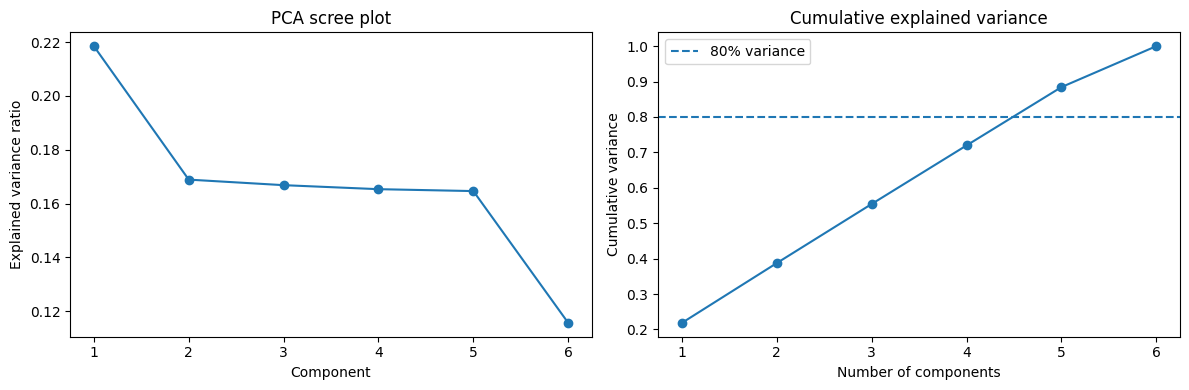

In [19]:
# scree plot and cumulative variance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    variance_table["Component"],
    variance_table["Explained variance ratio"],
    marker="o"
)
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("PCA scree plot")

axes[1].plot(
    variance_table["Component"],
    variance_table["Cumulative variance"],
    marker="o"
)
axes[1].axhline(
    y=0.80, linestyle="--", label="80% variance"
)
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance")
axes[1].set_title("Cumulative explained variance")
axes[1].legend()

plt.tight_layout()
plt.show()

Task 6 PCA

PCA needs 5 components to keep at least 80% of the total variance. Four components explain about 71.97%, while five explain about 88.43%
The first component explains only about 21.85%, so the variance is spread across several components. PCA therefore only reduces the number of features from 6 to 5 at this threshold

In [20]:
#7
scaled_data = pd.DataFrame(
    X_scaled,
    index=df.index,
    columns=num_cols
)

X_kernel = scaled_data.loc[sample.index].to_numpy()

gamma = 0.5

K_linear = X_kernel @ X_kernel.T

squared_norms = np.sum(X_kernel ** 2, axis=1)

sq_dists = (
    squared_norms[:, None] +
    squared_norms[None, :] -
    2 * K_linear
)

# remove tiny negative values from rounding
sq_dists = np.maximum(sq_dists, 0)

K_rbf = np.exp(-gamma * sq_dists)

print("Linear kernel:")
display(pd.DataFrame(
    K_linear,
    index=row_numbers,
    columns=row_numbers
).round(4))

print("RBF kernel:")
display(pd.DataFrame(
    K_rbf,
    index=row_numbers,
    columns=row_numbers
).round(6))

Linear kernel:


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,3.0236,0.3088,1.2005,-1.5092,0.0592,-2.0266,2.1730,1.0548,0.9445,-0.4375
4685,0.3088,4.9606,2.3941,0.5395,-2.6140,0.9301,-0.9717,-2.5854,-2.1927,1.6086
1732,1.2005,2.3941,3.2964,0.2594,-2.1835,0.3457,-0.6104,-1.4742,-0.3944,-0.3459
4743,-1.5092,0.5395,0.2594,9.5953,0.0406,-0.5749,0.7172,-3.0012,-2.6991,3.4600
4522,0.0592,-2.6140,-2.1835,0.0406,4.1415,-1.9056,3.8233,3.6003,0.3041,2.2236
6341,-2.0266,0.9301,0.3457,-0.5749,-1.9056,6.0739,-6.0829,-1.8202,-2.6847,-3.5199
577,2.1730,-0.9717,-0.6104,0.7172,3.8233,-6.0829,7.7219,3.4902,1.5989,5.0207
5203,1.0548,-2.5854,-1.4742,-3.0012,3.6003,-1.8202,3.4902,4.2831,1.3742,0.6757
6364,0.9445,-2.1927,-0.3944,-2.6991,0.3041,-2.6847,1.5989,1.3742,3.5093,-0.9713
440,-0.4375,1.6086,-0.3459,3.4600,2.2236,-3.5199,5.0207,0.6757,-0.9713,6.3871


RBF kernel:


,6253,4685,1732,4743,4522,6341,577,5203,6364,440
6253,1.000000,0.025139,0.140929,0.000402,0.029499,0.001394,0.040770,0.074378,0.098081,0.005841
4685,0.025139,1.000000,0.176497,0.001184,0.000773,0.010182,0.000667,0.000741,0.001616,0.017158
1732,0.140929,0.176497,1.000000,0.002057,0.002733,0.013044,0.002199,0.005175,0.022433,0.005585
4743,0.000402,0.001184,0.002057,1.000000,0.001083,0.000223,0.000356,0.000048,0.000096,0.010767
4522,0.029499,0.000773,0.002733,0.001083,1.000000,0.000900,0.121425,0.542253,0.029561,0.047801
6341,0.001394,0.010182,0.013044,0.000223,0.000900,1.000000,0.000002,0.000913,0.000566,0.000058
577,0.040770,0.000667,0.002199,0.000356,0.121425,0.000002,1.000000,0.081079,0.018011,0.130831
5203,0.074378,0.000741,0.005175,0.000048,0.542253,0.000913,0.081079,1.000000,0.080299,0.009471
6364,0.098081,0.001616,0.022433,0.000096,0.029561,0.000566,0.018011,0.080299,1.000000,0.002686
440,0.005841,0.017158,0.005585,0.010767,0.047801,0.000058,0.130831,0.009471,0.002686,1.000000


In [21]:
# most different pair
i_values, j_values = np.triu_indices(10, k=1)

pair_distances = sq_dists[i_values, j_values]
position = pair_distances.argmax()

i = i_values[position]
j = j_values[position]

print("Most different rows:", row_numbers[i], row_numbers[j])
print("Euclidean distance:", np.sqrt(sq_dists[i, j]))
print("Linear kernel:", K_linear[i, j])
print("RBF kernel:", K_rbf[i, j])

Most different rows: 6341 577
Euclidean distance: 5.095252627704856
Linear kernel: -6.0829097051283645
RBF kernel: 2.3041477949675853e-06


Task 7 Kernel Functions

The most different pair is rows 6341 and 577, with a standardized Euclidean distance of about 5.095. Their linear kernel is about -6.083, while their RBF kernel is about 0.0000023
The linear kernel is a dot product, so opposite deviations from the feature means can give a negative value. The RBF kernel depends on squared distance and stays between 0 and 1, so a large distance gives a value close to zero. Both indicate low similarity, but their values are on different scales

In [22]:
#8
age_zscore = (
    (df["Age"] - df["Age"].mean()) /
    df["Age"].std()
)

zscore_mask = age_zscore.abs() > 3

iqr_mask = (
    (df["Age"] < lower_bound) |
    (df["Age"] > upper_bound)
)

outlier_counts = pd.DataFrame({
    "Method": ["Z-score", "IQR"],
    "Number of outliers": [
        zscore_mask.sum(),
        iqr_mask.sum()
    ]
})

display(outlier_counts)

,Method,Number of outliers
0,Z-score,133
1,IQR,359


In [23]:
# rows flagged by only one method
different_mask = zscore_mask != iqr_mask

different_outliers = df.loc[
    different_mask, ["RowNumber", "Age"]
].copy()

different_outliers["Z-score"] = age_zscore.loc[different_mask]
different_outliers["Flagged by Z-score"] = zscore_mask.loc[
    different_mask
]
different_outliers["Flagged by IQR"] = iqr_mask.loc[
    different_mask
]

display(different_outliers.head(10))

print(
    "Number flagged by only one method:",
    len(different_outliers)
)

,RowNumber,Age,Z-score,Flagged by Z-score,Flagged by IQR
58,59,66,2.581874,False,True
104,105,65,2.486526,False,True
181,182,65,2.486526,False,True
234,235,67,2.677223,False,True
243,244,67,2.677223,False,True
364,365,68,2.772572,False,True
385,386,66,2.581874,False,True
399,400,66,2.581874,False,True
559,560,70,2.963270,False,True
567,568,63,2.295828,False,True


Number flagged by only one method: 226


In [24]:
# example of a global outlier
global_example = df.loc[
    df["RowNumber"] == 6444,
    ["RowNumber", "Age"]
].copy()

global_example["Z-score"] = age_zscore.loc[
    global_example.index
]

display(global_example)

print("Mean age:", df["Age"].mean())
print("Standard deviation:", df["Age"].std())
print("IQR upper bound:", upper_bound)

,RowNumber,Age,Z-score
6443,6444,92,5.060944


Mean age: 38.9218
Standard deviation: 10.487806451704609
IQR upper bound: 62.0


Task 8 Outlier Analysis

The Z-score method found 133 outliers, while IQR found 359. Row 59 has an age of 66 and is flagged by IQR but not by Z-score. Its age is above the IQR upper bound of 62, but its absolute Z-score is below 3
Row 6444 has an age of 92 and is flagged by both methods. It is a global outlier in the Age attribute because it is far from the overall age distribution, with a Z-score of about 5.06. This classification does not depend on a specific customer group or a collection of unusual rows. Being an outlier does not necessarily mean the age is incorrect